In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns


In [2]:
titanic= sns.load_dataset('titanic')

In [3]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
titanic.groupby('sex')[['survived']].mean()

,survived
sex,
female,0.742038
male,0.188908


In [5]:
titanic.groupby(['sex','class'])['survived'].aggregate('mean').unstack()

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\602533180.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(['sex','class'])['survived'].aggregate('mean').unstack()


class,First,Second,Third
sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [6]:
titanic.pivot_table('survived',index='sex',columns='class',aggfunc='mean')

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\631544778.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table('survived',index='sex',columns='class',aggfunc='mean')


class,First,Second,Third
sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [7]:
age = pd.cut(titanic['age'],[0,18,80])
titanic.pivot_table('survived',['sex',age],'class')

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\3505507367.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table('survived',['sex',age],'class')


class               First    Second     Third
sex    age                                   
female (0, 18]   0.909091  1.000000  0.511628
       (18, 80]  0.972973  0.900000  0.423729
male   (0, 18]   0.800000  0.600000  0.215686
       (18, 80]  0.375000  0.071429  0.133663

In [8]:
fare = pd.qcut(titanic['fare'],2)

In [9]:
titanic.pivot_table('survived',['sex',age],[fare,'class'])

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\1199661220.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table('survived',['sex',age],[fare,'class'])


fare            (-0.001, 14.454]                     (14.454, 512.329]  \
class                      First    Second     Third             First   
sex    age                                                               
female (0, 18]               NaN  1.000000  0.714286          0.909091   
       (18, 80]              NaN  0.880000  0.444444          0.972973   
male   (0, 18]               NaN  0.000000  0.260870          0.800000   
       (18, 80]              0.0  0.098039  0.125000          0.391304   

fare                                 
class              Second     Third  
sex    age                           
female (0, 18]   1.000000  0.318182  
       (18, 80]  0.914286  0.391304  
male   (0, 18]   0.818182  0.178571  
       (18, 80]  0.030303  0.192308

In [10]:
titanic.pivot_table(index='sex',columns='class',aggfunc={'survived':sum,'fare':'mean'})

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\3324049244.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table(index='sex',columns='class',aggfunc={'survived':sum,'fare':'mean'})
C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\3324049244.py:1: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  titanic.pivot_table(index='sex',columns='class',aggfunc={'survived':sum,'fare':'mean'})


fare                       survived             
class        First     Second      Third    First Second Third
sex                                                           
female  106.125798  21.970121  16.118810       91     70    72
male     67.226127  19.741782  12.661633       45     17    47

In [11]:
titanic.pivot_table('survived',index='sex',columns='class',margins=True)

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\2264378057.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table('survived',index='sex',columns='class',margins=True)


class,First,Second,Third,All
sex,,,,
female,0.968085,0.921053,0.500000,0.742038
male,0.368852,0.157407,0.135447,0.188908
All,0.629630,0.472826,0.242363,0.383838


In [12]:
births = pd.read_csv(r"C:\Users\benkh\Python_Handbook\Handbook\data\births.csv")

In [13]:
births.head()

,year,month,day,gender,births
0,1969,1,1.0,F,4046
1,1969,1,1.0,M,4440
2,1969,1,2.0,F,4454
3,1969,1,2.0,M,4548
4,1969,1,3.0,F,4548


In [14]:
births['decade']=10*(births['year']//10)

In [15]:
births.pivot_table('births',index='decade',columns='gender',aggfunc='sum')

gender,F,M
decade,,
1960,1753634,1846572
1970,16263075,17121550
1980,18310351,19243452
1990,19479454,20420553
2000,18229309,19106428


In [16]:
births

,year,month,day,gender,births,decade
0,1969,1,1.0,F,4046,1960
1,1969,1,1.0,M,4440,1960
2,1969,1,2.0,F,4454,1960
3,1969,1,2.0,M,4548,1960
4,1969,1,3.0,F,4548,1960
...,...,...,...,...,...,...
15542,2008,10,NaN,M,183219,2000
15543,2008,11,NaN,F,158939,2000
15544,2008,11,NaN,M,165468,2000
15545,2008,12,NaN,F,173215,2000


In [17]:
%matplotlib inline

In [18]:
import matplotlib.pyplot as plt

In [19]:
plt.style.use('seaborn-v0_8-whitegrid')

NameError: name 'plot' is not defined

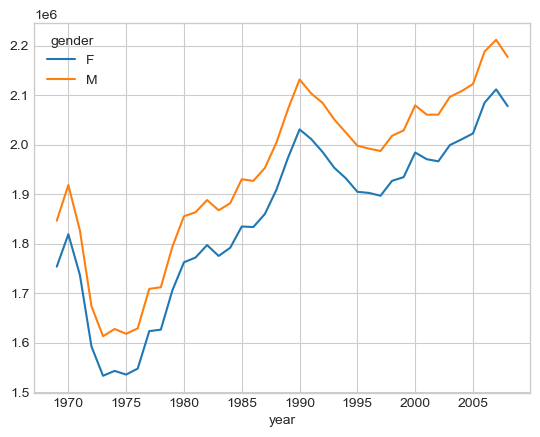

In [20]:
births.pivot_table('births',index='year',columns='gender',aggfunc='sum').plot()
plot.ylabel('total births per year')

In [21]:
quartiles = np. percentile(births['births'],[25,50,75])
mu = quartiles[1]
sig = 0.74 * (quartiles[2] - quartiles[0])

In [22]:
births = births.query('(births > @mu-5*@sig) & (births < @mu +5*@sig)')

In [23]:
births['day'] = births['day'].astype(int)

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\1457415740.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  births['day'] = births['day'].astype(int)


In [24]:
births.index = pd.to_datetime(10000*births.year+100*births.month+births.day,format='%Y%m%d')

In [25]:
births['dayofweek'] = births.index.dayofweek

C:\Users\benkh\AppData\Local\Temp\ipykernel_13984\147697732.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  births['dayofweek'] = births.index.dayofweek


In [26]:
import matplotlib.pyplot as plt
import matplotlib as mpl

Text(0, 0.5, 'mean births by day')

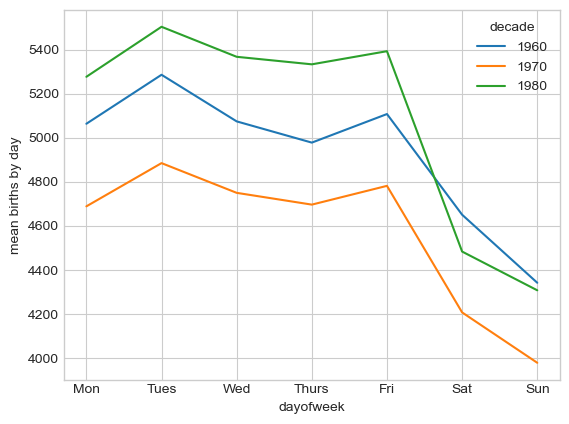

In [28]:
births.pivot_table('births',index = 'dayofweek',columns='decade',aggfunc='mean').plot()
plt.gca().set(xticks=range(7),
              xticklabels=['Mon','Tues','Wed','Thurs','Fri','Sat','Sun'])
plt.ylabel('mean births by day')

In [30]:
births_by_date=births.pivot_table('births',[births.index.month,births.index.day])

In [31]:
births_by_date.head()

births
1 1  4009.225
  2  4247.400
  3  4500.900
  4  4571.350
  5  4603.625

In [32]:
from datetime import datetime 
births_by_date.index = [datetime(2012,month,day) for (month,day) in births_by_date.index]

In [33]:
births_by_date.head()

,births
2012-01-01,4009.225
2012-01-02,4247.400
2012-01-03,4500.900
2012-01-04,4571.350
2012-01-05,4603.625


<Axes: >

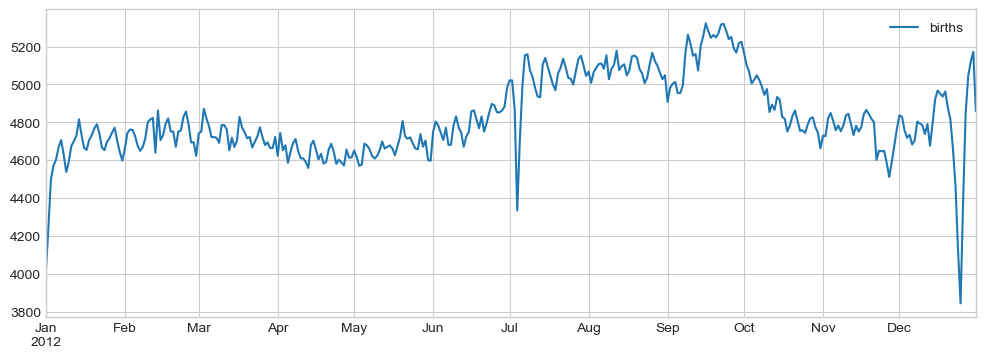

In [34]:
fig,ax = plt.subplots(figsize=(12,4))
births_by_date.plot(ax=ax)